In [1]:

import pandas as pd

dados = {
    "Codigo": ["PR001", "PR002", "PR003", "PR004", "PR005",
               "PR006", "PR007", "PR008", "PR009", "PR010"],

    "Produto": [
        "Camiseta oversized", "Camiseta polo", "Camiseta regata",
        "Calça jeans", "Calça cargo", "Calça de moletom",
        "Calça social", "Meia esportiva",
        "Meia de cano alto", "Meia soquete"
    ],

    "Estoque_Inicial": [80, 64, 48, 72, 56, 40, 32, 60, 44, 36],

    "Preco": [89.90, 99.90, 49.90, 159.90, 179.90,
              129.90, 199.90, 24.90, 29.90, 19.90]
}

df = pd.DataFrame(dados)

display(df)

print("Total de peças:", df["Estoque_Inicial"].sum())


,Codigo,Produto,Estoque_Inicial,Preco
0,PR001,Camiseta oversized,80,89.9
1,PR002,Camiseta polo,64,99.9
2,PR003,Camiseta regata,48,49.9
3,PR004,Calça jeans,72,159.9
4,PR005,Calça cargo,56,179.9
5,PR006,Calça de moletom,40,129.9
6,PR007,Calça social,32,199.9
7,PR008,Meia esportiva,60,24.9
8,PR009,Meia de cano alto,44,29.9
9,PR010,Meia soquete,36,19.9


Total de peças: 532


In [2]:

# Movimentações simuladas de julho de 2026

df["Entradas_Julho"] = [20, 12, 8, 15, 12, 7, 4, 14, 8, 6]

df["Saidas_Julho"] = [35, 22, 15, 27, 25, 10, 7, 24, 16, 12]

# Calcular o estoque restante
df["Saldo_Julho"] = (
    df["Estoque_Inicial"]
    + df["Entradas_Julho"]
    - df["Saidas_Julho"]
)

# Mostrar os resultados
display(df[["Codigo", "Produto", "Saldo_Julho"]])

print("Estoque final de julho:", df["Saldo_Julho"].sum())


,Codigo,Produto,Saldo_Julho
0,PR001,Camiseta oversized,65
1,PR002,Camiseta polo,54
2,PR003,Camiseta regata,41
3,PR004,Calça jeans,60
4,PR005,Calça cargo,43
5,PR006,Calça de moletom,37
6,PR007,Calça social,29
7,PR008,Meia esportiva,50
8,PR009,Meia de cano alto,36
9,PR010,Meia soquete,30


Estoque final de julho: 445


In [3]:

# Movimentações simuladas de agosto de 2026

df["Entradas_Agosto"] = [15, 10, 6, 9, 7, 5, 2, 10, 5, 6]

df["Saidas_Agosto"] = [40, 25, 17, 30, 28, 16, 9, 26, 19, 15]

# Calcular o estoque final de agosto
df["Saldo_Agosto"] = (
    df["Saldo_Julho"]
    + df["Entradas_Agosto"]
    - df["Saidas_Agosto"]
)

# Mostrar os resultados
display(df[["Codigo", "Produto", "Saldo_Julho", "Saldo_Agosto"]])

print("Estoque final de agosto:", df["Saldo_Agosto"].sum())



,Codigo,Produto,Saldo_Julho,Saldo_Agosto
0,PR001,Camiseta oversized,65,40
1,PR002,Camiseta polo,54,39
2,PR003,Camiseta regata,41,30
3,PR004,Calça jeans,60,39
4,PR005,Calça cargo,43,22
5,PR006,Calça de moletom,37,26
6,PR007,Calça social,29,22
7,PR008,Meia esportiva,50,34
8,PR009,Meia de cano alto,36,22
9,PR010,Meia soquete,30,21


Estoque final de agosto: 295


In [4]:

# Movimentações simuladas de setembro de 2026

df["Entradas_Setembro"] = [10, 8, 3, 6, 8, 6, 3, 9, 3, 4]

df["Saidas_Setembro"] = [43, 30, 24, 34, 26, 15, 14, 30, 25, 17]

# Calcular o estoque final de setembro
df["Saldo_Setembro"] = (
    df["Saldo_Agosto"]
    + df["Entradas_Setembro"]
    - df["Saidas_Setembro"]
)

# Mostrar os resultados
display(df[["Codigo", "Produto", "Saldo_Agosto", "Saldo_Setembro"]])

print("Estoque final de setembro:", df["Saldo_Setembro"].sum())


,Codigo,Produto,Saldo_Agosto,Saldo_Setembro
0,PR001,Camiseta oversized,40,7
1,PR002,Camiseta polo,39,17
2,PR003,Camiseta regata,30,9
3,PR004,Calça jeans,39,11
4,PR005,Calça cargo,22,4
5,PR006,Calça de moletom,26,17
6,PR007,Calça social,22,11
7,PR008,Meia esportiva,34,13
8,PR009,Meia de cano alto,22,0
9,PR010,Meia soquete,21,8


Estoque final de setembro: 97


In [5]:

import numpy as np

# Definir estoque mínimo de 10%
# Arredondar para cima quando necessário
df["Estoque_Minimo"] = np.ceil(
    df["Estoque_Inicial"] * 0.10
).astype(int)

# Classificar a situação de cada produto
df["Status"] = np.where(
    df["Saldo_Setembro"] == 0,
    "Esgotado",
    np.where(
        df["Saldo_Setembro"] <= df["Estoque_Minimo"],
        "Estoque baixo",
        "Normal"
    )
)

# Mostrar o resultado
display(df[[
    "Codigo",
    "Produto",
    "Saldo_Setembro",
    "Estoque_Minimo",
    "Status"
]])

print("\nResumo dos produtos:")
print(df["Status"].value_counts())


,Codigo,Produto,Saldo_Setembro,Estoque_Minimo,Status
0,PR001,Camiseta oversized,7,8,Estoque baixo
1,PR002,Camiseta polo,17,7,Normal
2,PR003,Camiseta regata,9,5,Normal
3,PR004,Calça jeans,11,8,Normal
4,PR005,Calça cargo,4,6,Estoque baixo
5,PR006,Calça de moletom,17,4,Normal
6,PR007,Calça social,11,4,Normal
7,PR008,Meia esportiva,13,6,Normal
8,PR009,Meia de cano alto,0,5,Esgotado
9,PR010,Meia soquete,8,4,Normal



Resumo dos produtos:
Status
Normal           7
Estoque baixo    2
Esgotado         1
Name: count, dtype: int64


In [7]:

# Criar cópia da tabela original
df_bruto = df.copy()

# Erro 1: produto sem nome
df_bruto.loc[
    df_bruto["Codigo"] == "PR003", "Produto"
] = None

# Erro 2: entrada com quantidade negativa
df_bruto.loc[
    df_bruto["Codigo"] == "PR004", "Entradas_Agosto"
] = -5

# Erro 3: cadastro duplicado
duplicado = df_bruto[df_bruto["Codigo"] == "PR002"]

df_bruto = pd.concat(
    [df_bruto, duplicado], ignore_index=True
)

# Identificar os problemas
print("Total de registros:", len(df_bruto))
print("Produtos sem nome:", df_bruto["Produto"].isna().sum())
print("Entradas negativas:", (df_bruto["Entradas_Agosto"] < 0).sum())
print("Códigos duplicados:", df_bruto["Codigo"].duplicated().sum())


Total de registros: 11
Produtos sem nome: 1
Entradas negativas: 1
Códigos duplicados: 1


In [8]:

# Criar uma cópia dos dados com erros
df_limpo = df_bruto.copy()

# Remover produtos duplicados
df_limpo = df_limpo.drop_duplicates(subset="Codigo")

# Recuperar informações da base original
referencia = df.set_index("Codigo")

df_limpo["Produto"] = df_limpo["Produto"].fillna(
    df_limpo["Codigo"].map(referencia["Produto"])
)

# Corrigir entradas negativas
erro = df_limpo["Entradas_Agosto"] < 0

df_limpo.loc[erro, "Entradas_Agosto"] = (
    df_limpo.loc[erro, "Codigo"].map(referencia["Entradas_Agosto"])
)

# Conferir os resultados
print("Total de registros:", len(df_limpo))
print("Produtos sem nome:", df_limpo["Produto"].isna().sum())
print("Entradas negativas:", (df_limpo["Entradas_Agosto"] < 0).sum())
print("Códigos duplicados:", df_limpo["Codigo"].duplicated().sum())


Total de registros: 10
Produtos sem nome: 0
Entradas negativas: 0
Códigos duplicados: 0


In [16]:

# Calcular os KPIs após o tratamento dos dados

total_produtos = len(df_limpo)

produtos_criticos = df_limpo["Status"].isin(
    ["Estoque baixo", "Esgotado"]
).sum()

taxa_criticos = (produtos_criticos / total_produtos) * 100

total_vendas = df_limpo[
    ["Saidas_Julho", "Saidas_Agosto", "Saidas_Setembro"]
].sum().sum()

total_entradas = df_limpo[
    ["Entradas_Julho", "Entradas_Agosto", "Entradas_Setembro"]
].sum().sum()

taxa_reposicao = (total_entradas / total_vendas) * 100

print(f"Produtos críticos: {taxa_criticos:.1f}%")
print(f"Peças vendidas: {total_vendas}")
print(f"Taxa de reposição: {taxa_reposicao:.1f}%")


Produtos críticos: 30.0%
Peças vendidas: 676
Taxa de reposição: 35.7%


In [9]:

# Calcular as vendas totais de cada produto
df_limpo["Total_Saidas"] = df_limpo[
    ["Saidas_Julho", "Saidas_Agosto", "Saidas_Setembro"]
].sum(axis=1)

# Calcular as estatísticas
media = df_limpo["Total_Saidas"].mean()
mediana = df_limpo["Total_Saidas"].median()
desvio = df_limpo["Total_Saidas"].std()

# Mostrar resultados
display(df_limpo[["Produto", "Total_Saidas"]])

print(f"Média de vendas: {media:.2f}")
print(f"Mediana de vendas: {mediana:.2f}")
print(f"Desvio padrão: {desvio:.2f}")


,Produto,Total_Saidas
0,Camiseta oversized,118
1,Camiseta polo,77
2,Camiseta regata,56
3,Calça jeans,91
4,Calça cargo,79
5,Calça de moletom,41
6,Calça social,30
7,Meia esportiva,80
8,Meia de cano alto,60
9,Meia soquete,44


Média de vendas: 67.60
Mediana de vendas: 68.50
Desvio padrão: 26.52


In [10]:

# Calcular a assimetria das vendas
assimetria = df_limpo["Total_Saidas"].skew()

print(f"Assimetria das vendas: {assimetria:.2f}")

# Interpretar o resultado
if assimetria > 0.5:
    print("Distribuição assimétrica à direita.")
elif assimetria < -0.5:
    print("Distribuição assimétrica à esquerda.")
else:
    print("Distribuição aproximadamente simétrica.")


Assimetria das vendas: 0.43
Distribuição aproximadamente simétrica.


In [11]:

from scipy.stats import pearsonr

# Comparar preço e quantidade vendida
correlacao, p_valor = pearsonr(
    df_limpo["Preco"],
    df_limpo["Total_Saidas"]
)

print(f"Correlação de Pearson: {correlacao:.2f}")
print(f"Valor-p: {p_valor:.4f}")


Correlação de Pearson: -0.04
Valor-p: 0.9077


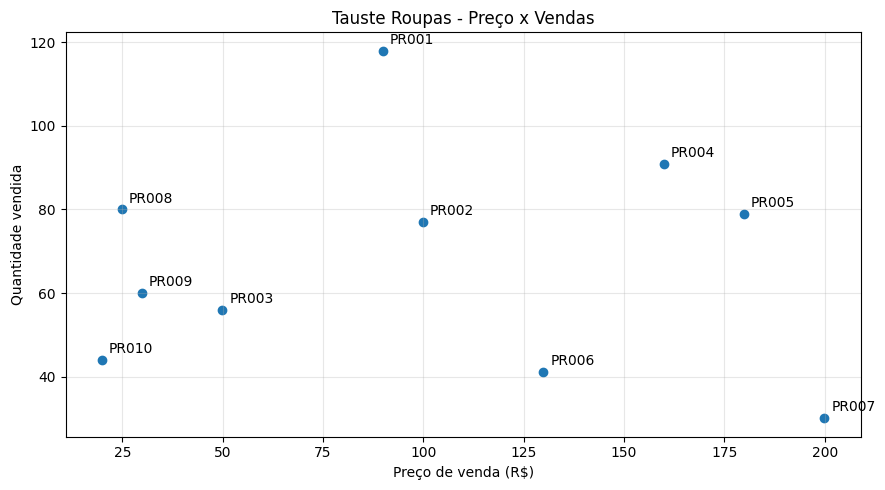

In [12]:

import matplotlib.pyplot as plt

# Criar gráfico de dispersão
plt.figure(figsize=(9, 5))

plt.scatter(
    df_limpo["Preco"],
    df_limpo["Total_Saidas"]
)

# Identificar cada produto no gráfico
for _, linha in df_limpo.iterrows():
    plt.annotate(
        linha["Codigo"],
        (linha["Preco"], linha["Total_Saidas"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Títulos e informações
plt.title("Tauste Roupas - Preço x Vendas")
plt.xlabel("Preço de venda (R$)")
plt.ylabel("Quantidade vendida")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


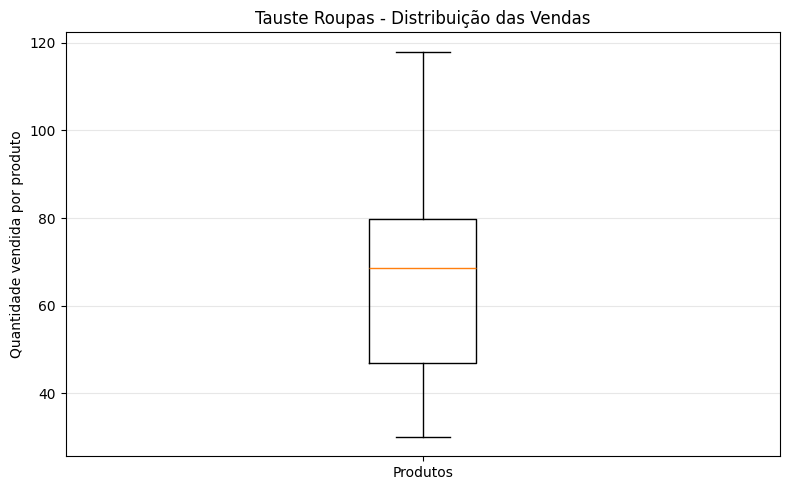

Limite inferior: -2.12
Limite superior: 128.88
Quantidade de outliers: 0


In [13]:

import matplotlib.pyplot as plt

# Criar gráfico Boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(df_limpo["Total_Saidas"])

plt.title("Tauste Roupas - Distribuição das Vendas")
plt.ylabel("Quantidade vendida por produto")
plt.xticks([1], ["Produtos"])

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Calcular os limites dos outliers
Q1 = df_limpo["Total_Saidas"].quantile(0.25)
Q3 = df_limpo["Total_Saidas"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df_limpo[
    (df_limpo["Total_Saidas"] < limite_inferior) |
    (df_limpo["Total_Saidas"] > limite_superior)
]

print("Limite inferior:", round(limite_inferior, 2))
print("Limite superior:", round(limite_superior, 2))
print("Quantidade de outliers:", len(outliers))


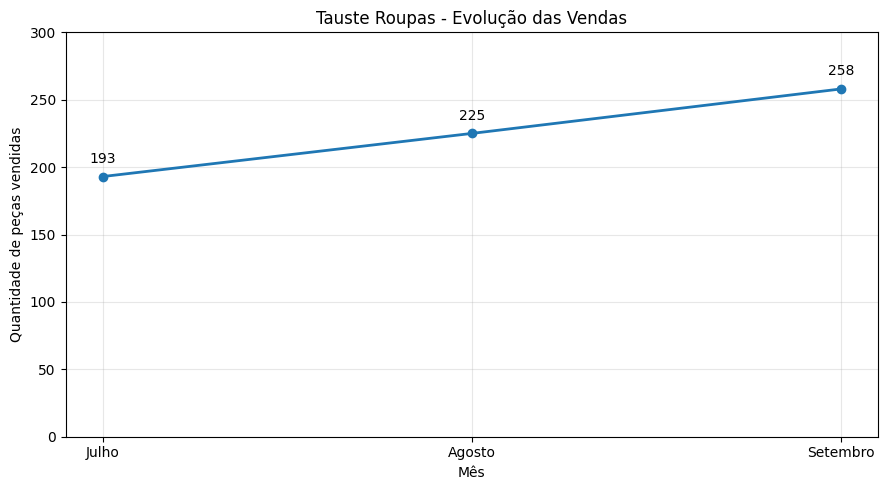

Vendas por mês: [np.int64(193), np.int64(225), np.int64(258)]


In [14]:

import matplotlib.pyplot as plt

# Calcular as vendas de cada mês
vendas_julho = df_limpo["Saidas_Julho"].sum()
vendas_agosto = df_limpo["Saidas_Agosto"].sum()
vendas_setembro = df_limpo["Saidas_Setembro"].sum()

meses = ["Julho", "Agosto", "Setembro"]
vendas = [vendas_julho, vendas_agosto, vendas_setembro]

# Criar o gráfico
plt.figure(figsize=(9, 5))

plt.plot(meses, vendas, marker="o", linewidth=2)

# Mostrar os valores dos pontos
for mes, quantidade in zip(meses, vendas):
    plt.annotate(
        str(quantidade),
        (mes, quantidade),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

plt.title("Tauste Roupas - Evolução das Vendas")
plt.xlabel("Mês")
plt.ylabel("Quantidade de peças vendidas")
plt.ylim(0, 300)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Vendas por mês:", vendas)


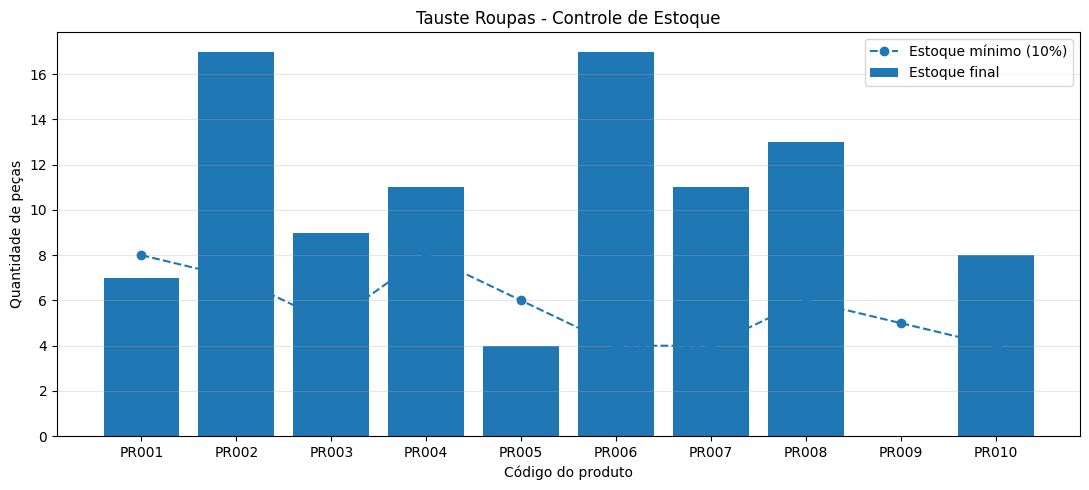

Produtos que precisam de atenção:


,Produto,Saldo_Setembro,Status
0,Camiseta oversized,7,Estoque baixo
4,Calça cargo,4,Estoque baixo
8,Meia de cano alto,0,Esgotado


In [15]:

import matplotlib.pyplot as plt

# Comparar estoque final e estoque mínimo
plt.figure(figsize=(11, 5))

plt.bar(
    df_limpo["Codigo"],
    df_limpo["Saldo_Setembro"],
    label="Estoque final"
)

plt.plot(
    df_limpo["Codigo"],
    df_limpo["Estoque_Minimo"],
    marker="o",
    linestyle="--",
    label="Estoque mínimo (10%)"
)

plt.title("Tauste Roupas - Controle de Estoque")
plt.xlabel("Código do produto")
plt.ylabel("Quantidade de peças")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Mostrar produtos que precisam de atenção
print("Produtos que precisam de atenção:")

display(df_limpo[
    df_limpo["Status"] != "Normal"
][["Produto", "Saldo_Setembro", "Status"]])


### 2.1 — Justificativa dos Indicadores (KPIs)

**KPI 1 — Percentual de produtos críticos (30%)**

Esse indicador foi escolhido para identificar a proporção de produtos com estoque baixo ou esgotado. Ele está relacionado ao objetivo do projeto de oferecer alertas de reposição e melhorar o controle do estoque.

**KPI 2 — Quantidade de peças vendidas (676 unidades)**

Esse indicador permite acompanhar o volume de saídas de mercadorias entre julho e setembro de 2026. Ele ajuda a avaliar a movimentação dos produtos e a importância do registro de entradas e saídas no sistema.

**KPI 3 — Taxa de reposição (35,7%)**

Esse indicador compara a quantidade de mercadorias recebidas com a quantidade vendida. O resultado demonstra que, na simulação, a reposição foi insuficiente para acompanhar as saídas, aumentando o risco de falta de produtos.



### 2.4 — Análise Crítica dos Resultados

A análise dos dados simulados da Tauste Roupas identificou como principal gargalo operacional a insuficiência na reposição de mercadorias. Entre julho e setembro de 2026, foram registradas 676 saídas e apenas 241 entradas, resultando em uma taxa de reposição de 35,7%. Consequentemente, o estoque caiu de 532 para 97 unidades, e 30% dos modelos terminaram o período com estoque baixo ou esgotado. A correlação de Pearson entre preço e quantidade vendida foi de −0,04, indicando ausência de uma relação linear relevante nessa amostra. Além disso, o Boxplot não identificou outliers nas quantidades vendidas pelo método IQR.

Esses resultados justificam o escopo estabelecido no Termo de Abertura do Projeto (TAP), na Disciplina 1, que prevê o desenvolvimento de um protótipo funcional até 30 de novembro de 2026. O sistema proposto pela Riot Soluções de TI permitirá registrar entradas e saídas, acompanhar produtos por tamanho e cor e emitir alertas de estoque baixo ou esgotado. Os indicadores calculados demonstram a importância dessas funcionalidades para apoiar o acompanhamento do estoque e a tomada de decisões de reposição. Todos os resultados apresentados são fictícios e foram desenvolvidos para fins acadêmicos.

### Bibliotecas e Metodologia

Para desenvolver a análise de dados da Tauste Roupas, utilizei informações fictícias de 10 modelos de produtos, simulando as entradas e saídas de mercadorias entre julho e setembro de 2026.

Durante o projeto, utilizei algumas bibliotecas do Python:

- **Pandas:** para organizar as informações, criar tabelas e analisar os dados.
- **NumPy:** para realizar cálculos e identificar produtos com estoque baixo ou esgotado.
- **SciPy:** para verificar a relação entre os preços e as quantidades vendidas.
- **Matplotlib:** para criar gráficos e facilitar a visualização dos resultados.

Também realizei uma etapa de limpeza dos dados, na qual identifiquei produtos duplicados, informações que estavam faltando e uma entrada de mercadorias com valor negativo. Corrigi esses problemas utilizando os dados originais da simulação.

Todo o trabalho foi desenvolvido e testado por mim no Google Colab, utilizando Python. Com isso, consegui analisar a movimentação do estoque, identificar os produtos que precisam de reposição e apresentar os resultados de forma mais clara.

### Relação dos KPIs com o Objetivo SMART

Na Disciplina 1, defini como objetivo desenvolver um protótipo funcional de controle de estoque até 30 de novembro de 2026. A ideia é facilitar a organização dos produtos da Tauste Roupas e evitar problemas relacionados à falta de mercadorias.

Durante a análise dos dados, utilizei três indicadores para entender melhor a situação do estoque. O primeiro mostrou que 30% dos produtos estavam com estoque baixo ou esgotado, reforçando a importância de criar alertas automáticos. O segundo registrou 676 peças vendidas durante os três meses analisados, demonstrando a necessidade de acompanhar as saídas de mercadorias. Já o terceiro apresentou uma taxa de reposição de 35,7%, indicando que a entrada de novos produtos não acompanhou o volume de vendas.

Com esses resultados, consegui identificar problemas que ajudam a justificar as funcionalidades previstas no projeto. Os indicadores também poderão ser utilizados para avaliar o controle de estoque realizado pelo sistema. Já o cumprimento do prazo de desenvolvimento será verificado separadamente, conforme o cronograma definido na Disciplina 1.

In [17]:

import pandas as pd

# Salvar os dados originais com erros
df_bruto.to_csv(
    "tauste_dados_brutos.csv",
    index=False,
    encoding="utf-8-sig"
)

# Ler os dados do arquivo CSV
df_extraido = pd.read_csv(
    "tauste_dados_brutos.csv",
    encoding="utf-8-sig"
)

# Salvar os dados que foram tratados
df_limpo.to_csv(
    "tauste_dados_limpos.csv",
    index=False,
    encoding="utf-8-sig"
)

# Conferir os resultados
print("Dados brutos:", len(df_extraido), "registros")
print("Dados tratados:", len(df_limpo), "registros")
print("Arquivos CSV criados com sucesso!")


Dados brutos: 11 registros
Dados tratados: 10 registros
Arquivos CSV criados com sucesso!


### Processo ETL — Tratamento de Dados

Para realizar o tratamento dos dados da Tauste Roupas, utilizei a biblioteca Pandas do Python. Primeiro, organizei as informações dos produtos e criei uma base com alguns erros simulados, como um cadastro duplicado, um produto sem nome e uma entrada de mercadorias com quantidade negativa.

Depois, utilizei o Python para identificar e corrigir esses problemas, recuperando as informações corretas da base original. Com isso, consegui reduzir os registros de 11 para 10, sem deixar informações duplicadas ou valores inválidos.

Por último, salvei os dados em dois arquivos CSV: um com os registros brutos e outro com os dados tratados. Dessa forma, consegui demonstrar o processo de extração, transformação e carga (ETL), preparando as informações para as análises estatísticas e os indicadores do projeto.

In [18]:

# Controle por tamanho e cor - Camiseta oversized

variacoes = pd.DataFrame({
    "Codigo": ["PR001"] * 8,
    "Produto": ["Camiseta oversized"] * 8,
    "Cor": ["Preta"] * 4 + ["Branca"] * 4,
    "Tamanho": ["P", "M", "G", "GG"] * 2,
    "Quantidade": [8, 14, 14, 8, 6, 12, 12, 6]
})

# Mostrar as variações cadastradas
display(variacoes)

# Conferir a quantidade total
print("Total de unidades:", variacoes["Quantidade"].sum())


,Codigo,Produto,Cor,Tamanho,Quantidade
0,PR001,Camiseta oversized,Preta,P,8
1,PR001,Camiseta oversized,Preta,M,14
2,PR001,Camiseta oversized,Preta,G,14
3,PR001,Camiseta oversized,Preta,GG,8
4,PR001,Camiseta oversized,Branca,P,6
5,PR001,Camiseta oversized,Branca,M,12
6,PR001,Camiseta oversized,Branca,G,12
7,PR001,Camiseta oversized,Branca,GG,6


Total de unidades: 80


In [19]:

# Distribuição dos outros 9 produtos

estoques = {
    "PR002": {
        "Azul-marinho": [5, 10, 10, 7],
        "Preta": [5, 10, 10, 7]
    },
    "PR003": {
        "Branca": [4, 8, 8, 4],
        "Cinza": [4, 8, 8, 4]
    },
    "PR004": {
        "Azul": [7, 13, 13, 8],
        "Preta": [5, 10, 10, 6]
    },
    "PR005": {
        "Verde-militar": [5, 10, 10, 6],
        "Bege": [4, 8, 8, 5]
    },
    "PR006": {
        "Cinza": [3, 6, 6, 5],
        "Preta": [3, 6, 6, 5]
    },
    "PR007": {
        "Preta": [3, 5, 5, 4],
        "Azul-marinho": [2, 5, 5, 3]
    },
    "PR008": {
        "Branca": [13, 18],
        "Preta": [12, 17]
    },
    "PR009": {
        "Branca": [10, 13],
        "Cinza": [9, 12]
    },
    "PR010": {
        "Preta": [9, 10],
        "Branca": [8, 9]
    }
}

linhas = []

for codigo, cores in estoques.items():

    produto = df.loc[
        df["Codigo"] == codigo, "Produto"
    ].iloc[0]

    if codigo in ["PR008", "PR009", "PR010"]:
        tamanhos = ["34-38", "39-43"]
    elif codigo in ["PR004", "PR005", "PR006", "PR007"]:
        tamanhos = ["38", "40", "42", "44"]
    else:
        tamanhos = ["P", "M", "G", "GG"]

    for cor, quantidades in cores.items():
        for tamanho, quantidade in zip(tamanhos, quantidades):
            linhas.append({
                "Codigo": codigo,
                "Produto": produto,
                "Cor": cor,
                "Tamanho": tamanho,
                "Quantidade": quantidade
            })

# Juntar com a camiseta oversized (PR001)
outras_variacoes = pd.DataFrame(linhas)

variacoes_completas = pd.concat(
    [variacoes, outras_variacoes],
    ignore_index=True
)

# Conferir os totais por produto
resumo = variacoes_completas.groupby(
    ["Codigo", "Produto"], as_index=False
)["Quantidade"].sum()

display(resumo)

print("Total de variações:", len(variacoes_completas))
print("Total de peças:", variacoes_completas["Quantidade"].sum())


,Codigo,Produto,Quantidade
0,PR001,Camiseta oversized,80
1,PR002,Camiseta polo,64
2,PR003,Camiseta regata,48
3,PR004,Calça jeans,72
4,PR005,Calça cargo,56
5,PR006,Calça de moletom,40
6,PR007,Calça social,32
7,PR008,Meia esportiva,60
8,PR009,Meia de cano alto,44
9,PR010,Meia soquete,36


Total de variações: 68
Total de peças: 532


In [20]:

# Somar o estoque de todas as variações
estoque_variacoes = variacoes_completas.groupby(
    "Codigo"
)["Quantidade"].sum().reset_index()

# Comparar com o estoque inicial cadastrado
conferencia = pd.merge(
    df[["Codigo", "Estoque_Inicial"]],
    estoque_variacoes,
    on="Codigo"
)

# Calcular possíveis diferenças
conferencia["Diferenca"] = (
    conferencia["Estoque_Inicial"]
    - conferencia["Quantidade"]
)

# Mostrar a conferência
display(conferencia)

# Verificar inconsistências
erros = (conferencia["Diferenca"] != 0).sum()

print("Produtos com divergência:", erros)

if erros == 0:
    print("Estoque conferido com sucesso!")
else:
    print("Existem quantidades para revisar.")


,Codigo,Estoque_Inicial,Quantidade,Diferenca
0,PR001,80,80,0
1,PR002,64,64,0
2,PR003,48,48,0
3,PR004,72,72,0
4,PR005,56,56,0
5,PR006,40,40,0
6,PR007,32,32,0
7,PR008,60,60,0
8,PR009,44,44,0
9,PR010,36,36,0


Produtos com divergência: 0
Estoque conferido com sucesso!


In [21]:

import numpy as np

# Distribuir quantidades proporcionalmente
def distribuir(total, pesos):
    pesos = np.array(pesos, dtype=float)

    if pesos.sum() == 0:
        pesos = np.ones(len(pesos))

    proporcoes = total * pesos / pesos.sum()
    resultado = np.floor(proporcoes).astype(int)

    restante = int(total - resultado.sum())

    ordem = np.argsort(
        -(proporcoes - resultado), kind="stable"
    )

    resultado[ordem[:restante]] += 1

    return resultado


# Criar tabela para julho
variacoes_julho = variacoes_completas.copy()

variacoes_julho["Entradas_Julho"] = 0
variacoes_julho["Saidas_Julho"] = 0

for codigo, grupo in variacoes_julho.groupby("Codigo"):

    indices = grupo.index
    produto = df[df["Codigo"] == codigo].iloc[0]

    entradas = distribuir(
        int(produto["Entradas_Julho"]),
        grupo["Quantidade"]
    )

    disponivel = grupo["Quantidade"].to_numpy() + entradas

    saidas = distribuir(
        int(produto["Saidas_Julho"]),
        disponivel
    )

    variacoes_julho.loc[indices, "Entradas_Julho"] = entradas
    variacoes_julho.loc[indices, "Saidas_Julho"] = saidas


# Calcular saldo final de cada variação
variacoes_julho["Saldo_Julho"] = (
    variacoes_julho["Quantidade"]
    + variacoes_julho["Entradas_Julho"]
    - variacoes_julho["Saidas_Julho"]
)

# Conferir os resultados
print("Total de entradas:", variacoes_julho["Entradas_Julho"].sum())
print("Total de saídas:", variacoes_julho["Saidas_Julho"].sum())
print("Estoque final:", variacoes_julho["Saldo_Julho"].sum())

print(
    "Variações com estoque negativo:",
    (variacoes_julho["Saldo_Julho"] < 0).sum()
)


Total de entradas: 106
Total de saídas: 193
Estoque final: 445
Variações com estoque negativo: 0


In [22]:

# Movimentações de agosto por tamanho e cor

variacoes_agosto = variacoes_julho.copy()

variacoes_agosto["Entradas_Agosto"] = 0
variacoes_agosto["Saidas_Agosto"] = 0

for codigo, grupo in variacoes_agosto.groupby("Codigo"):

    indices = grupo.index
    produto = df[df["Codigo"] == codigo].iloc[0]

    # Distribuir as entradas de agosto
    entradas = distribuir(
        int(produto["Entradas_Agosto"]),
        grupo["Saldo_Julho"]
    )

    # Quantidade disponível após a reposição
    disponivel = grupo["Saldo_Julho"].to_numpy() + entradas

    # Distribuir as saídas de agosto
    saidas = distribuir(
        int(produto["Saidas_Agosto"]),
        disponivel
    )

    variacoes_agosto.loc[indices, "Entradas_Agosto"] = entradas
    variacoes_agosto.loc[indices, "Saidas_Agosto"] = saidas

# Calcular o estoque final de agosto
variacoes_agosto["Saldo_Agosto"] = (
    variacoes_agosto["Saldo_Julho"]
    + variacoes_agosto["Entradas_Agosto"]
    - variacoes_agosto["Saidas_Agosto"]
)

# Conferir os resultados
print("Total de entradas:", variacoes_agosto["Entradas_Agosto"].sum())
print("Total de saídas:", variacoes_agosto["Saidas_Agosto"].sum())
print("Estoque final:", variacoes_agosto["Saldo_Agosto"].sum())

print(
    "Variações com estoque negativo:",
    (variacoes_agosto["Saldo_Agosto"] < 0).sum()
)


Total de entradas: 75
Total de saídas: 225
Estoque final: 295
Variações com estoque negativo: 0


In [23]:

# Movimentações de setembro por tamanho e cor

variacoes_setembro = variacoes_agosto.copy()

variacoes_setembro["Entradas_Setembro"] = 0
variacoes_setembro["Saidas_Setembro"] = 0

for codigo, grupo in variacoes_setembro.groupby("Codigo"):

    indices = grupo.index
    produto = df[df["Codigo"] == codigo].iloc[0]

    # Distribuir as entradas de setembro
    entradas = distribuir(
        int(produto["Entradas_Setembro"]),
        grupo["Saldo_Agosto"]
    )

    # Estoque disponível após a reposição
    disponivel = grupo["Saldo_Agosto"].to_numpy() + entradas

    # Distribuir as saídas de setembro
    saidas = distribuir(
        int(produto["Saidas_Setembro"]),
        disponivel
    )

    variacoes_setembro.loc[indices, "Entradas_Setembro"] = entradas
    variacoes_setembro.loc[indices, "Saidas_Setembro"] = saidas

# Calcular o estoque final de setembro
variacoes_setembro["Saldo_Setembro"] = (
    variacoes_setembro["Saldo_Agosto"]
    + variacoes_setembro["Entradas_Setembro"]
    - variacoes_setembro["Saidas_Setembro"]
)

# Conferir os resultados
print("Total de entradas:", variacoes_setembro["Entradas_Setembro"].sum())
print("Total de saídas:", variacoes_setembro["Saidas_Setembro"].sum())
print("Estoque final:", variacoes_setembro["Saldo_Setembro"].sum())

print(
    "Variações com estoque negativo:",
    (variacoes_setembro["Saldo_Setembro"] < 0).sum()
)


Total de entradas: 60
Total de saídas: 258
Estoque final: 97
Variações com estoque negativo: 0


In [24]:

# Identificar tamanhos e cores esgotados

variacoes_esgotadas = variacoes_setembro[
    variacoes_setembro["Saldo_Setembro"] == 0
].copy()

# Consultar o saldo total de cada modelo
saldos_modelos = df.set_index("Codigo")["Saldo_Setembro"]

variacoes_esgotadas["Saldo_Modelo"] = (
    variacoes_esgotadas["Codigo"].map(saldos_modelos)
)

print("Total de variações esgotadas:", len(variacoes_esgotadas))

display(variacoes_esgotadas[[
    "Codigo",
    "Produto",
    "Cor",
    "Tamanho",
    "Saldo_Setembro"
]])

# Verificar variações esgotadas de modelos ainda disponíveis
esgotadas_parciais = variacoes_esgotadas[
    variacoes_esgotadas["Saldo_Modelo"] > 0
]

print(
    "Variações esgotadas com modelo ainda disponível:",
    len(esgotadas_parciais)
)

display(esgotadas_parciais[[
    "Produto",
    "Cor",
    "Tamanho",
    "Saldo_Modelo"
]])


Total de variações esgotadas: 11


,Codigo,Produto,Cor,Tamanho,Saldo_Setembro
4,PR001,Camiseta oversized,Branca,P,0
32,PR005,Calça cargo,Verde-militar,38,0
35,PR005,Calça cargo,Verde-militar,44,0
36,PR005,Calça cargo,Bege,38,0
39,PR005,Calça cargo,Bege,44,0
44,PR006,Calça de moletom,Preta,38,0
48,PR007,Calça social,Preta,38,0
60,PR009,Meia de cano alto,Branca,34-38,0
61,PR009,Meia de cano alto,Branca,39-43,0
62,PR009,Meia de cano alto,Cinza,34-38,0


Variações esgotadas com modelo ainda disponível: 7


,Produto,Cor,Tamanho,Saldo_Modelo
4,Camiseta oversized,Branca,P,7
32,Calça cargo,Verde-militar,38,4
35,Calça cargo,Verde-militar,44,4
36,Calça cargo,Bege,38,4
39,Calça cargo,Bege,44,4
44,Calça de moletom,Preta,38,17
48,Calça social,Preta,38,11


In [25]:

# Definir estoque mínimo de 10% por variação

variacoes_setembro["Minimo_Variacao"] = np.ceil(
    variacoes_setembro["Quantidade"] * 0.10
).astype(int)

# Classificar o estoque de cada tamanho e cor

variacoes_setembro["Status_Variacao"] = np.select(
    [
        variacoes_setembro["Saldo_Setembro"] == 0,
        variacoes_setembro["Saldo_Setembro"] <=
        variacoes_setembro["Minimo_Variacao"]
    ],
    ["Esgotado", "Estoque baixo"],
    default="Normal"
)

# Mostrar resumo dos alertas
print("Situação das 68 variações:")
print(variacoes_setembro["Status_Variacao"].value_counts())

# Mostrar apenas as variações que precisam de atenção
alertas = variacoes_setembro[
    variacoes_setembro["Status_Variacao"] != "Normal"
]

display(alertas[[
    "Codigo",
    "Produto",
    "Cor",
    "Tamanho",
    "Saldo_Setembro",
    "Minimo_Variacao",
    "Status_Variacao"
]])


Situação das 68 variações:
Status_Variacao
Estoque baixo    31
Normal           26
Esgotado         11
Name: count, dtype: int64


,Codigo,Produto,Cor,Tamanho,Saldo_Setembro,Minimo_Variacao,Status_Variacao
0,PR001,Camiseta oversized,Preta,P,1,1,Estoque baixo
1,PR001,Camiseta oversized,Preta,M,1,2,Estoque baixo
2,PR001,Camiseta oversized,Preta,G,1,2,Estoque baixo
3,PR001,Camiseta oversized,Preta,GG,1,1,Estoque baixo
4,PR001,Camiseta oversized,Branca,P,0,1,Esgotado
5,PR001,Camiseta oversized,Branca,M,1,2,Estoque baixo
6,PR001,Camiseta oversized,Branca,G,1,2,Estoque baixo
7,PR001,Camiseta oversized,Branca,GG,1,1,Estoque baixo
8,PR002,Camiseta polo,Azul-marinho,P,1,1,Estoque baixo
12,PR002,Camiseta polo,Preta,P,1,1,Estoque baixo


In [26]:

# Somar o saldo final das variações por produto
resumo_variacoes = variacoes_setembro.groupby(
    "Codigo", as_index=False
)["Saldo_Setembro"].sum()

resumo_variacoes = resumo_variacoes.rename(
    columns={"Saldo_Setembro": "Saldo_Variacoes"}
)

# Comparar com os saldos dos 10 modelos
conferencia_final = df[
    ["Codigo", "Produto", "Saldo_Setembro"]
].merge(
    resumo_variacoes,
    on="Codigo"
)

# Verificar possíveis diferenças
conferencia_final["Diferenca"] = (
    conferencia_final["Saldo_Setembro"]
    - conferencia_final["Saldo_Variacoes"]
)

display(conferencia_final)

print(
    "Estoque final:",
    conferencia_final["Saldo_Variacoes"].sum()
)

print(
    "Produtos com divergência:",
    (conferencia_final["Diferenca"] != 0).sum()
)


,Codigo,Produto,Saldo_Setembro,Saldo_Variacoes,Diferenca
0,PR001,Camiseta oversized,7,7,0
1,PR002,Camiseta polo,17,17,0
2,PR003,Camiseta regata,9,9,0
3,PR004,Calça jeans,11,11,0
4,PR005,Calça cargo,4,4,0
5,PR006,Calça de moletom,17,17,0
6,PR007,Calça social,11,11,0
7,PR008,Meia esportiva,13,13,0
8,PR009,Meia de cano alto,0,0,0
9,PR010,Meia soquete,8,8,0


Estoque final: 97
Produtos com divergência: 0


### Análise do Estoque por Tamanho e Cor

Para complementar a análise de dados da Tauste Roupas, organizei os 10 modelos de produtos em 68 variações, considerando os tamanhos e as cores disponíveis. Inicialmente, cadastrei 532 peças e simulei as movimentações de entrada e saída entre julho e setembro de 2026. As movimentações foram distribuídas proporcionalmente entre as variações para representar o funcionamento do controle de estoque.

Ao final da análise, identifiquei 26 variações com estoque normal, 31 com estoque baixo e 11 esgotadas. Também observei que sete variações estavam esgotadas, mesmo quando ainda existiam unidades do mesmo modelo em outros tamanhos ou cores.

Por último, conferi os resultados com o estoque geral e confirmei que as 68 variações totalizavam 97 peças, sem nenhuma divergência. Com essa análise, consegui demonstrar a importância de controlar cada tamanho e cor separadamente, conforme as funcionalidades que defini na Disciplina 1.

Todos os dados utilizados são fictícios e foram criados para fins acadêmicos.